In [5]:
# Web based Jupyter Notebook.
import micropip; 
await micropip.install('pandas')
#await micropip.install('pandas==0.24.2', reinstall=True, keep_going=True)
await micropip.install('pandas_ml')
await micropip.install('matplotlib')
await micropip.install('seaborn')
await micropip.install('pydot')
await micropip.install('graphviz')
await micropip.install('scikit-learn')
await micropip.install('scikit-plot')

In [14]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

import pandas as pd, numpy as np
import sys
import io

import matplotlib.pyplot as plt 
import seaborn as sns 
import pydot
from sklearn.tree import export_graphviz
from mpl_toolkits.mplot3d import Axes3D

In [52]:
def two_d_compare(X_Test_slr, Y_Test_slr, Y_Pred_slr, model_name):
    area = (12 * np.random.rand(40))**2
    plt.subplots(ncols=2, figsize=(10,4))
    plt.suptitle('Actual vs Predicted Data: '+ model_name + ' Variance Score : %.2f' % r2_score(Y_Test_slr, Y_Pred_slr))

    plt.subplot(121)
    plt.scatter(X_Test_slr, Y_Test_slr, alpha=0.8, color='#8CCB9B' )
    plt.title('Actual')
    
    plt.subplot(122)
    plt.scatter(X_Test_slr, Y_Pred_slr, alpha=0.8, color='#E5E88B' )
    plt.title('Predicted')

    plt.show()

def model_metrics(regressor, Y_Test_slr, Y_Pred_slr):
    mse = mean_squared_error(Y_Test_slr, Y_Pred_slr)
    print("Mean Squared Error: %.2f " % mse)
    r2 = r2_score(Y_Test_slr, Y_Pred_slr)
    print('R2 score: %.2f' % r2)

    return [mse, r2]

def two_vs_three_d(x_test, y_test, y_pred, z = None, isLinear = False):
    area = 60
   
    fig = plt.figure(figsize=(12,6))
    fig.suptitle('2D and 3D view of sales price data')

    # First subplot
    ax = fig.add_subplot(1, 2,1)
    ax.scatter(x_test, y_test, alpha=0.5,color='blue', s= area)
    ax.plot(x_test, y_pred, alpha=0.9,color='red', linewidth=2)
    ax.set_xlabel('YEAR BUILT')
    ax.set_ylabel('SELLING PRICE')
    
    plt.title('YEARBUILT vs SALEPRICE')
    
    if not isLinear : 
    # Second subplot
        ax = fig.add_subplot(1,2,2, projection='3d')

        ax.scatter(z, x_test, y_test, color='blue', marker='o')
        ax.plot(z, x_test, y_pred, alpha=0.9,color='red', linewidth=2)
        ax.set_ylabel('YEAR BUILT')
        ax.set_zlabel('SELLING PRICE')
        ax.set_xlabel('LOT AREA')

    plt.title('LOT AREA vs YEAR BUILT vs SELLING PRICE')

    plt.show()    

In [15]:
#Download from the following IBM GitHub URL: https://github.com/IBM/ml-learning-path-assets

df_pd=pd.read_csv('predict_home_value.csv')      #The variable in the code shared by the excerise project.
df_pd.head()


,ID,LOTAREA,BLDGTYPE,HOUSESTYLE,OVERALLCOND,YEARBUILT,ROOFSTYLE,EXTERCOND,FOUNDATION,BSMTCOND,...,GARAGETYPE,GARAGEFINISH,GARAGECARS,GARAGECOND,POOLAREA,POOLQC,FENCE,MOSOLD,YRSOLD,SALEPRICE
0,1,8450,1Fam,2Story,5,2003,Gable,TA,PConc,TA,...,Attchd,RFn,2,TA,0,NaN,NaN,2,2008,208500
1,2,9600,1Fam,1Story,8,1976,Gable,TA,CBlock,TA,...,Attchd,RFn,2,TA,0,NaN,NaN,5,2007,181500
2,3,11250,1Fam,2Story,5,2001,Gable,TA,PConc,TA,...,Attchd,RFn,2,TA,0,NaN,NaN,9,2008,223500
3,4,9550,1Fam,2Story,5,1915,Gable,TA,BrkTil,Gd,...,Detchd,Unf,3,TA,0,NaN,NaN,2,2006,140000
4,5,14260,1Fam,2Story,5,2000,Gable,TA,PConc,TA,...,Attchd,RFn,3,TA,0,NaN,NaN,12,2008,250000


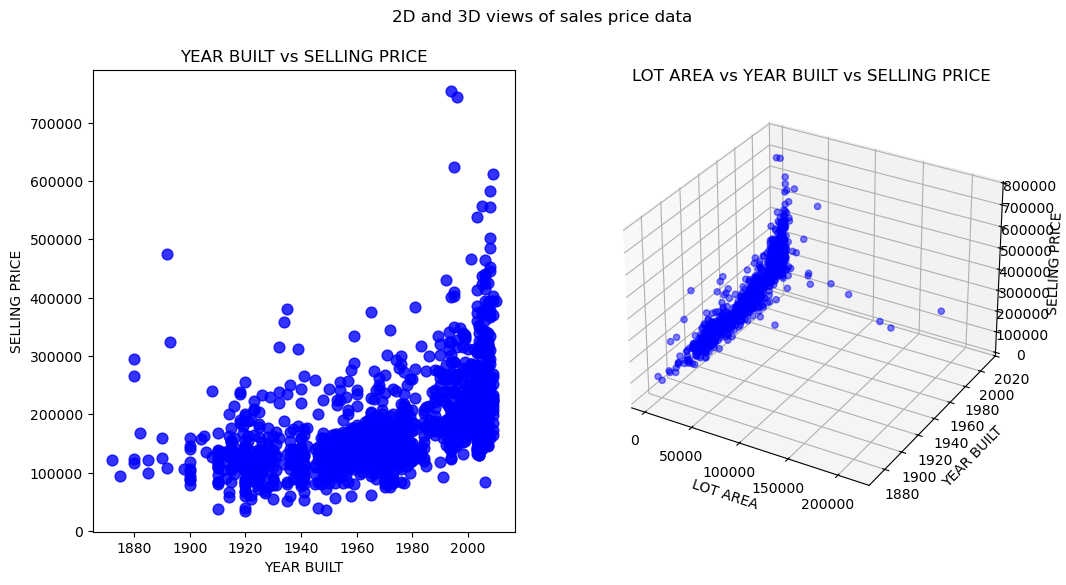

In [17]:
area = 60

x = df_pd['YEARBUILT']
y = df_pd['SALEPRICE']
z = df_pd['LOTAREA']

fig = plt.figure(figsize=(12,6))
plt.suptitle('2D and 3D views of sales price data')

#First subplot
ax = fig.add_subplot(1, 2, 1)
ax.scatter(x, y, alpha=0.8, color='blue', s=area)
ax.set_xlabel('YEAR BUILT')
ax.set_ylabel('SELLING PRICE')

plt.title('YEAR BUILT vs SELLING PRICE')

#Second subplot
ax = fig.add_subplot(1,2,2, projection='3d')
ax.scatter(z, x, y, alpha=0.5, color='blue', marker='o')
ax.set_xlabel('LOT AREA')
ax.set_ylabel('YEAR BUILT')
ax.set_zlabel('SELLING PRICE')

plt.title('LOT AREA vs YEAR BUILT vs SELLING PRICE')

plt.show()


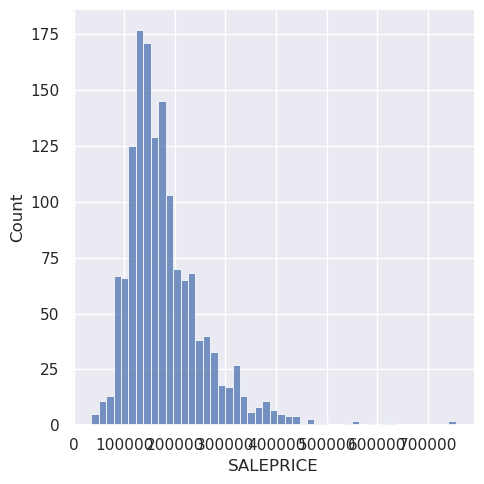

In [19]:
sns.set(rc = {"figure.figsize": (8, 4) } ) ; np.random.seed(0)
ax = sns.displot(df_pd['SALEPRICE'])
plt.show()


In [23]:
print('The dataset used contains columns of following data types: \n' + str(df_pd.dtypes))

The dataset used contains columns of following data types: 
ID              int64
LOTAREA         int64
BLDGTYPE          str
HOUSESTYLE        str
OVERALLCOND     int64
YEARBUILT       int64
ROOFSTYLE         str
EXTERCOND         str
FOUNDATION        str
BSMTCOND          str
HEATING           str
HEATINGQC         str
CENTRALAIR        str
ELECTRICAL        str
FULLBATH        int64
HALFBATH        int64
BEDROOMABVGR    int64
KITCHENABVGR    int64
KITCHENQUAL       str
TOTRMSABVGRD    int64
FIREPLACES      int64
FIREPLACEQU       str
GARAGETYPE        str
GARAGEFINISH      str
GARAGECARS      int64
GARAGECOND        str
POOLAREA        int64
POOLQC            str
FENCE             str
MOSOLD          int64
YRSOLD          int64
SALEPRICE       int64
dtype: object


In [24]:
print('The number of records in each data columns used: \n' + str(df_pd.count()))

The number of records in each data columns used: 
ID              1460
LOTAREA         1460
BLDGTYPE        1460
HOUSESTYLE      1460
OVERALLCOND     1460
YEARBUILT       1460
ROOFSTYLE       1460
EXTERCOND       1460
FOUNDATION      1460
BSMTCOND        1423
HEATING         1460
HEATINGQC       1460
CENTRALAIR      1460
ELECTRICAL      1459
FULLBATH        1460
HALFBATH        1460
BEDROOMABVGR    1460
KITCHENABVGR    1460
KITCHENQUAL     1460
TOTRMSABVGRD    1460
FIREPLACES      1460
FIREPLACEQU      770
GARAGETYPE      1379
GARAGEFINISH    1379
GARAGECARS      1460
GARAGECOND      1379
POOLAREA        1460
POOLQC             7
FENCE            281
MOSOLD          1460
YRSOLD          1460
SALEPRICE       1460
dtype: int64


In [25]:
df_pd.isnull().any()

ID              False
LOTAREA         False
BLDGTYPE        False
HOUSESTYLE      False
OVERALLCOND     False
YEARBUILT       False
ROOFSTYLE       False
EXTERCOND       False
FOUNDATION      False
BSMTCOND         True
HEATING         False
HEATINGQC       False
CENTRALAIR      False
ELECTRICAL       True
FULLBATH        False
HALFBATH        False
BEDROOMABVGR    False
KITCHENABVGR    False
KITCHENQUAL     False
TOTRMSABVGRD    False
FIREPLACES      False
FIREPLACEQU      True
GARAGETYPE       True
GARAGEFINISH     True
GARAGECARS      False
GARAGECOND       True
POOLAREA        False
POOLQC           True
FENCE            True
MOSOLD          False
YRSOLD          False
SALEPRICE       False
dtype: bool

In [26]:
# Data prepration.

#Removing column's that aren't required to reduce dimensionality
df_pd = df_pd.drop(['ID'], axis=1)

df_pd.head()


,LOTAREA,BLDGTYPE,HOUSESTYLE,OVERALLCOND,YEARBUILT,ROOFSTYLE,EXTERCOND,FOUNDATION,BSMTCOND,HEATING,...,GARAGETYPE,GARAGEFINISH,GARAGECARS,GARAGECOND,POOLAREA,POOLQC,FENCE,MOSOLD,YRSOLD,SALEPRICE
0,8450,1Fam,2Story,5,2003,Gable,TA,PConc,TA,GasA,...,Attchd,RFn,2,TA,0,NaN,NaN,2,2008,208500
1,9600,1Fam,1Story,8,1976,Gable,TA,CBlock,TA,GasA,...,Attchd,RFn,2,TA,0,NaN,NaN,5,2007,181500
2,11250,1Fam,2Story,5,2001,Gable,TA,PConc,TA,GasA,...,Attchd,RFn,2,TA,0,NaN,NaN,9,2008,223500
3,9550,1Fam,2Story,5,1915,Gable,TA,BrkTil,Gd,GasA,...,Detchd,Unf,3,TA,0,NaN,NaN,2,2006,140000
4,14260,1Fam,2Story,5,2000,Gable,TA,PConc,TA,GasA,...,Attchd,RFn,3,TA,0,NaN,NaN,12,2008,250000


In [29]:
# Defining the categorical columns.
#categoricalColumns = df_pd.select_dtypes(include=[object]).columns       #Deprecated.
categoricalColumns = df_pd.select_dtypes(include=[object, 'str']).columns

print('<<Categorical Columns>>')
print(categoricalColumns)

impute_categorical = SimpleImputer(strategy="most_frequent")
one_hot_categorical = OneHotEncoder(handle_unknown='ignore')

categorical_transformer = Pipeline(steps=[('impute', impute_categorical), ('onehot', one_hot_categorical)])


<<Categorical Columns>>
Index(['BLDGTYPE', 'HOUSESTYLE', 'ROOFSTYLE', 'EXTERCOND', 'FOUNDATION',
       'BSMTCOND', 'HEATING', 'HEATINGQC', 'CENTRALAIR', 'ELECTRICAL',
       'KITCHENQUAL', 'FIREPLACEQU', 'GARAGETYPE', 'GARAGEFINISH',
       'GARAGECOND', 'POOLQC', 'FENCE'],
      dtype='str')


In [32]:
#Define the numerical columns.
numericalColumns = [col for col in df_pd.select_dtypes(include=[float, int]).columns if col not in ['SALEPRICE']]
print("<<Numerical Columns>>")
print(numericalColumns)

scaler_numerical = StandardScaler()

numerical_transformer = Pipeline(steps=[('scale', scaler_numerical)])

<<Numerical Columns>>
['LOTAREA', 'OVERALLCOND', 'YEARBUILT', 'FULLBATH', 'HALFBATH', 'BEDROOMABVGR', 'KITCHENABVGR', 'TOTRMSABVGRD', 'FIREPLACES', 'GARAGECARS', 'POOLAREA', 'MOSOLD', 'YRSOLD']


In [34]:
preprocessorForCategoricalColumns = ColumnTransformer(transformers=[('cat', categorical_transformer, categoricalColumns)], 
                                                      remainder="passthrough")

preprocessorForAllColumns = ColumnTransformer(transformers=[('cat', categorical_transformer, categoricalColumns), 
                                              ('num', numerical_transformer, numericalColumns)], remainder="passthrough")

#The transformation happens in the pipeline, showing here temporarily.

df_churn_pd_temp = preprocessorForCategoricalColumns.fit_transform(df_pd)
print("<<Data After Transforming Categorical Columns>>")
print(df_churn_pd_temp)

df_churn_pd_temp2 = preprocessorForAllColumns.fit_transform(df_pd)
print("\n\n<<Data After Transforming All Columns>>")
print(df_churn_pd_temp2)

<<Data After Transforming Categorical Columns>>
[[1.00000e+00 0.00000e+00 0.00000e+00 ... 2.00000e+00 2.00800e+03
  2.08500e+05]
 [1.00000e+00 0.00000e+00 0.00000e+00 ... 5.00000e+00 2.00700e+03
  1.81500e+05]
 [1.00000e+00 0.00000e+00 0.00000e+00 ... 9.00000e+00 2.00800e+03
  2.23500e+05]
 ...
 [1.00000e+00 0.00000e+00 0.00000e+00 ... 5.00000e+00 2.01000e+03
  2.66500e+05]
 [1.00000e+00 0.00000e+00 0.00000e+00 ... 4.00000e+00 2.01000e+03
  1.42125e+05]
 [1.00000e+00 0.00000e+00 0.00000e+00 ... 6.00000e+00 2.00800e+03
  1.47500e+05]]


<<Data After Transforming All Columns>>
[[ 1.00000000e+00  0.00000000e+00  0.00000000e+00 ... -1.59911110e+00
   1.38777489e-01  2.08500000e+05]
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00 ... -4.89110051e-01
  -6.14438622e-01  1.81500000e+05]
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00 ...  9.90891347e-01
   1.38777489e-01  2.23500000e+05]
 ...
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00 ... -4.89110051e-01
   1.64520971e+00  2.6650000

In [36]:
#Prepare data frame into train and test sets.

features = []
features = df_pd.drop(['SALEPRICE'], axis=1)

label = pd.DataFrame(df_pd, columns=['SALEPRICE'])
#label_encoder = LabelEncoder()
label = df_pd['SALEPRICE']

#label = label_encoder.fit_transform(label)
print('Value of label: ' + str(label) )

Value of label: 0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SALEPRICE, Length: 1460, dtype: int64


In [67]:
#Training the model.
X_Train_mlr, X_Test_mlr, Y_Train_mlr, Y_Test_mlr = train_test_split(features, label, random_state=0)

print("Dimensions for the dataset which will be used for training: Input Features"+str(X_Train_mlr.shape)+
      "Output Label"+str(Y_Train_mlr.shape))
print("Dimensions for the dataset which will be used for testing: Input Features"+str(X_Test_mlr.shape)+
      "Output Label"+str(Y_Test_mlr.shape))


Dimensions for the dataset which will be used for training: Input Features(1095, 30)Output Label(1095,)
Dimensions for the dataset which will be used for testing: Input Features(365, 30)Output Label(365,)


In [68]:
#Training the model.

from sklearn.linear_model import LinearRegression

model_name = "Multiple Linear Regression"

mlr_Regressor = LinearRegression()

mlr_model = Pipeline(steps=[('preprocessorAll', preprocessorForAllColumns), ('regressor', mlr_Regressor)])

mlr_model.fit(X_Train_mlr, Y_Train_mlr)

Y_Pred_mlr = mlr_model.predict(X_Test_mlr)

print(mlr_Regressor)

LinearRegression()


In [69]:
print('Intercept: \n', mlr_Regressor.intercept_)
print('Coefficients: \n', mlr_Regressor.coef_)



Intercept: 
 156627.42043324726
Coefficients: 
 [  6267.87762611   2479.02414028   8797.73682332 -13253.1028037
  -4291.53578601   1191.535428    10629.88326392   3704.92868167
   7521.17938534 -12518.89284555  -5642.12349275   1823.79826104
  -6710.30868167   5056.58738348 -10078.5923191   -5922.44615431
   8873.17819182  -5356.73886612   7428.01176423 -19881.67837283
   1752.31386936   4020.69343405  15527.12401852  -1418.4529491
  -8023.33503413 -12920.48700529   -898.64229306 -35266.89648222
   4057.40469667  53051.95611803 -11175.90971138  -5573.40920826
  20792.49758601  -4043.17866636 -30149.1652352   -1634.62606952
  15688.54691618  -5180.43106563  42447.99945794 -21172.32400375
  13082.87697853   5137.82260514   6216.23012462 -33753.80869668
   9316.8789884    1605.40034326  -1605.40034326   6924.16027651
  11189.83222898  -1056.78783363 -18716.82987875   1659.62520689
  44219.2385728  -16274.54076754  -7992.07787044 -19952.61993481
  50301.85361684 -15135.56856164  -6255.3009

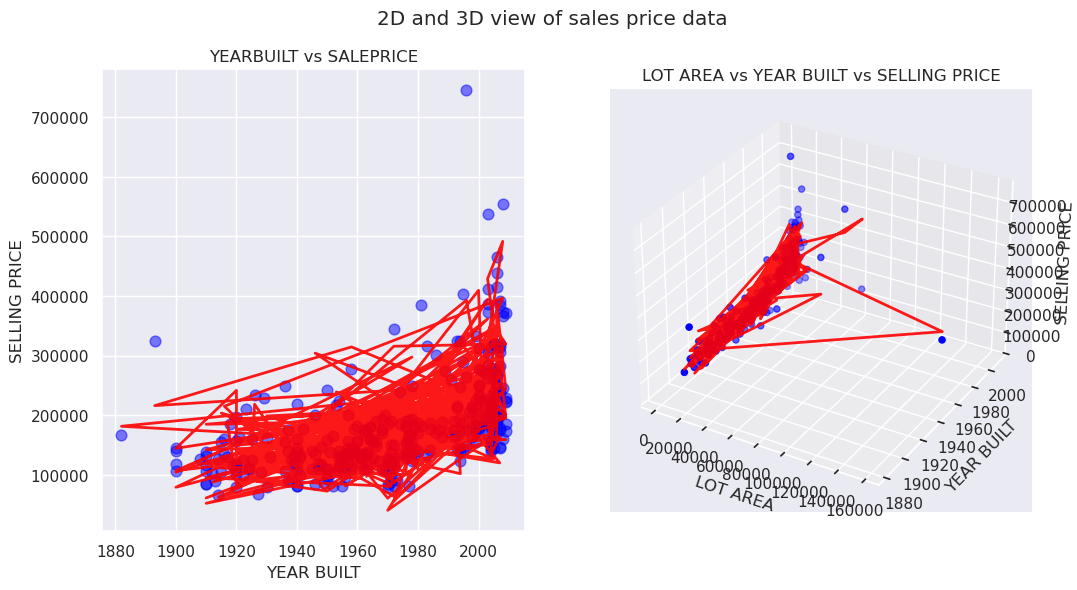

In [60]:
two_vs_three_d(X_Test_mlr['YEARBUILT'], Y_Test_mlr, Y_Pred_mlr, X_Test_mlr['LOTAREA'], False)

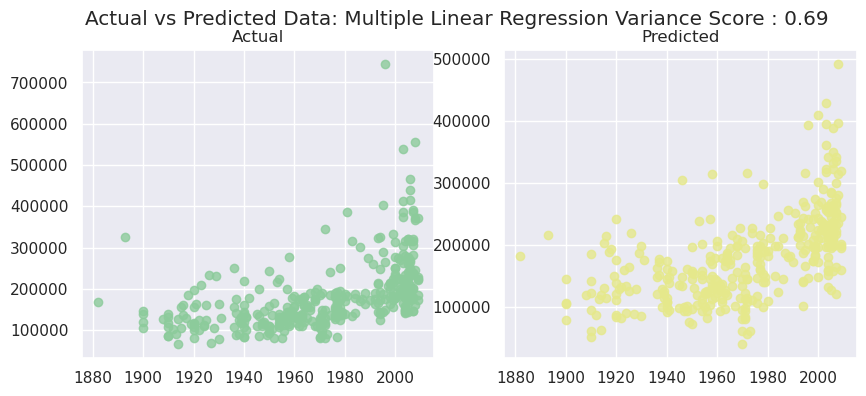

In [63]:
two_d_compare(X_Test_mlr['YEARBUILT'], Y_Test_mlr, Y_Pred_mlr, model_name)

In [65]:
mlr_Metrics = model_metrics(mlr_Regressor, Y_Test_mlr, Y_Pred_mlr)

Mean Squared Error: 2041070045.89 
R2 score: 0.69
